In [1]:
# Basic Libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


### Load Dataset

In [2]:
df = pd.read_csv("IBM Telco_customer_churn_dataset.csv")
pd.set_option('display.max_columns', None)
# Preview data
df.head()

,CustomerID,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


### Basic Exploration

In [3]:
# Check the Dataset Shape
print("Shape:", df.shape)
print("\nColumns:\n", df.columns)

Shape: (7043, 32)

Columns:
 Index(['CustomerID', 'Country', 'State', 'City', 'Zip Code', 'Lat Long',
       'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner',
       'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines',
       'Internet Service', 'Online Security', 'Online Backup',
       'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
       'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges',
       'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV',
       'Churn Reason'],
      dtype='str')


In [4]:
# Churn distribution
print("\nChurn Distribution:\n", df['Churn Value'].value_counts())


Churn Distribution:
 Churn Value
0    5174
1    1869
Name: count, dtype: int64


In [5]:
# Check missing values
print("\nMissing Values:\n", df.isnull().sum())


Missing Values:
 CustomerID              0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


### Data Cleaning

In [6]:
print(df.columns.tolist())

['CustomerID', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [7]:
# Remove spaces from column names
df.columns = df.columns.str.strip()

# Optional: standardize (recommended)
df.columns = df.columns.str.replace(" ", "")

In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

C:\Users\Hp\AppData\Local\Temp\ipykernel_9788\1099764709.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


0        108.15
1        151.65
2        820.50
3       3046.05
4       5036.30
         ...   
7038    1419.40
7039    1990.50
7040    7362.90
7041     346.45
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [9]:
drop_cols = ['customerID', 'Churn Reason', 'Churn Category','ChurnValue']
df.drop(columns=[col for col in drop_cols if col in df.columns], inplace=True)

### Exploratory Data Analysis (EDA)

#### Churn Distribution

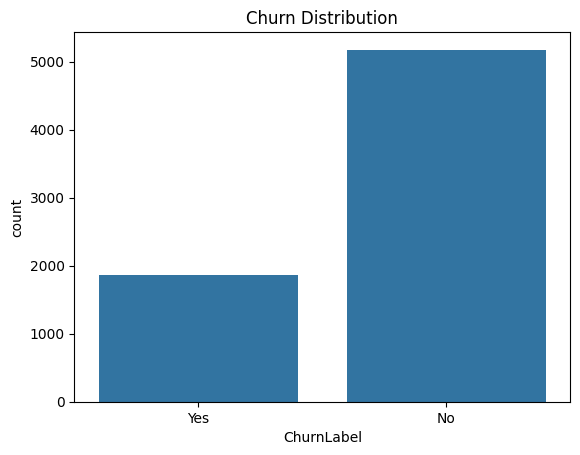

In [10]:
sns.countplot(x='ChurnLabel',data=df)  # or correct one
plt.title("Churn Distribution")
plt.show()

#### Churn by Contract Type

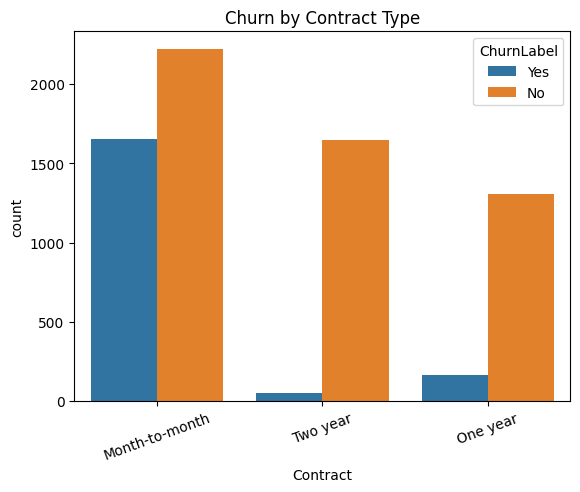

In [11]:
sns.countplot(x='Contract', hue='ChurnLabel', data=df)
plt.title("Churn by Contract Type")
plt.xticks(rotation=20)
plt.show()

#### Monthly Charges vs Churn

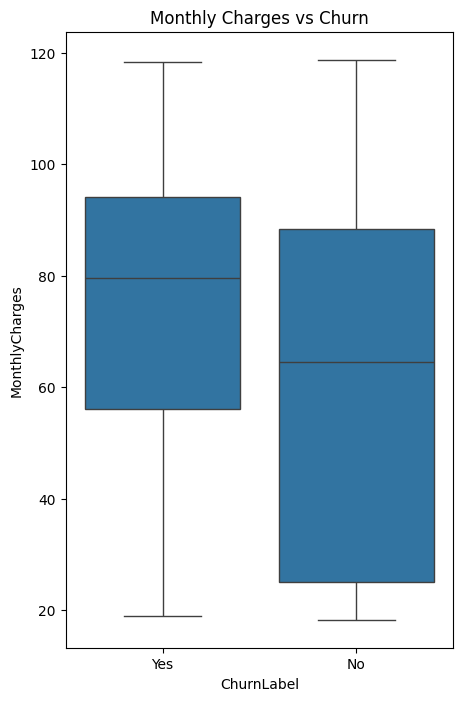

In [12]:
plt.figure(figsize=(5,8))
sns.boxplot(x='ChurnLabel', y='MonthlyCharges', data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

### Encoding Categorical Variables

In [13]:
# Convert target variable
df['ChurnLabel'] = df['ChurnLabel'].map({'Yes': 1, 'No': 0})

# Label Encoding for binary columns
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        if df[col].nunique() == 2:
            df[col] = le.fit_transform(df[col])

# One-hot encoding for remaining categorical variables
df = pd.get_dummies(df, drop_first=True)

df.head()

,ZipCode,Latitude,Longitude,TenureMonths,MonthlyCharges,TotalCharges,ChurnLabel,ChurnScore,CLTV,CustomerID_0003-MKNFE,CustomerID_0004-TLHLJ,CustomerID_0011-IGKFF,CustomerID_0013-EXCHZ,CustomerID_0013-MHZWF,CustomerID_0013-SMEOE,CustomerID_0014-BMAQU,CustomerID_0015-UOCOJ,CustomerID_0016-QLJIS,CustomerID_0017-DINOC,CustomerID_0017-IUDMW,CustomerID_0018-NYROU,CustomerID_0019-EFAEP,CustomerID_0019-GFNTW,CustomerID_0020-INWCK,CustomerID_0020-JDNXP,CustomerID_0021-IKXGC,CustomerID_0022-TCJCI,CustomerID_0023-HGHWL,CustomerID_0023-UYUPN,CustomerID_0023-XUOPT,CustomerID_0027-KWYKW,CustomerID_0030-FNXPP,CustomerID_0031-PVLZI,CustomerID_0032-PGELS,CustomerID_0036-IHMOT,CustomerID_0040-HALCW,CustomerID_0042-JVWOJ,CustomerID_0042-RLHYP,CustomerID_0048-LUMLS,CustomerID_0048-PIHNL,CustomerID_0052-DCKON,CustomerID_0052-YNYOT,CustomerID_0056-EPFBG,CustomerID_0057-QBUQH,CustomerID_0058-EVZWM,CustomerID_0060-FUALY,CustomerID_0064-SUDOG,CustomerID_0064-YIJGF,CustomerID_0067-DKWBL,CustomerID_0068-FIGTF,CustomerID_0071-NDAFP,CustomerID_0074-HDKDG,CustomerID_0076-LVEPS,CustomerID_0078-XZMHT,CustomerID_0080-EMYVY,CustomerID_0080-OROZO,CustomerID_0082-LDZUE,CustomerID_0082-OQIQY,CustomerID_0083-PIVIK,CustomerID_0089-IIQKO,CustomerID_0093-EXYQL,CustomerID_0093-XWZFY,CustomerID_0094-OIFMO,CustomerID_0096-BXERS,CustomerID_0096-FCPUF,CustomerID_0098-BOWSO,CustomerID_0100-DUVFC,CustomerID_0103-CSITQ,CustomerID_0104-PPXDV,CustomerID_0106-GHRQR,CustomerID_0106-UGRDO,CustomerID_0107-WESLM,CustomerID_0107-YHINA,CustomerID_0111-KLBQG,CustomerID_0112-QAWRZ,CustomerID_0112-QWPNC,CustomerID_0114-IGABW,CustomerID_0114-PEGZZ,CustomerID_0114-RSRRW,CustomerID_0115-TFERT,CustomerID_0117-LFRMW,CustomerID_0118-JPNOY,CustomerID_0121-SNYRK,CustomerID_0122-OAHPZ,CustomerID_0123-CRBRT,CustomerID_0125-LZQXK,CustomerID_0128-MKWSG,CustomerID_0129-KPTWJ,CustomerID_0129-QMPDR,CustomerID_0130-SXOUN,CustomerID_0133-BMFZO,CustomerID_0134-XWXCE,CustomerID_0135-NMXAP,CustomerID_0136-IFMYD,CustomerID_0137-OCGAB,CustomerID_0137-UDEUO,CustomerID_0139-IVFJG,CustomerID_0141-YEAYS,CustomerID_0142-GVYSN,CustomerID_0147-ESWWR,CustomerID_0148-DCDOS,CustomerID_0151-ONTOV,CustomerID_0156-FVPTA,CustomerID_0164-APGRB,CustomerID_0164-XAIRP,CustomerID_0168-XZKBB,CustomerID_0174-QRVVY,CustomerID_0177-PXBAT,CustomerID_0178-CIIKR,CustomerID_0178-SZBHO,CustomerID_0181-RITDD,CustomerID_0186-CAERR,CustomerID_0187-QSXOE,CustomerID_0187-WZNAB,CustomerID_0188-GWFLE,CustomerID_0191-EQUUH,CustomerID_0191-ZHSKZ,CustomerID_0193-ESZXP,CustomerID_0195-IESCP,CustomerID_0196-JTUQI,CustomerID_0196-VULGZ,CustomerID_0197-PNKNK,CustomerID_0201-MIBOL,CustomerID_0201-OAMXR,CustomerID_0203-HHYIJ,CustomerID_0206-OYVOC,CustomerID_0206-TBWLC,CustomerID_0207-MDKNV,CustomerID_0208-BPQEJ,CustomerID_0212-ISBBF,CustomerID_0214-JHPFW,CustomerID_0215-BQKGS,CustomerID_0218-QNVAS,CustomerID_0219-QAERP,CustomerID_0219-YTZUE,CustomerID_0220-EBGCE,CustomerID_0221-NAUXK,CustomerID_0221-WMXNQ,CustomerID_0222-CNVPT,CustomerID_0224-HJAPT,CustomerID_0224-NIJLP,CustomerID_0224-RLWWD,CustomerID_0225-ZORZP,CustomerID_0228-MAUWC,CustomerID_0229-LFJAF,CustomerID_0230-UBYPQ,CustomerID_0230-WEQUW,CustomerID_0231-LXVAP,CustomerID_0233-FTHAV,CustomerID_0234-TEVTT,CustomerID_0235-KGSLC,CustomerID_0236-HFWSV,CustomerID_0237-YFUTL,CustomerID_0238-WHBIQ,CustomerID_0239-OXEXL,CustomerID_0244-LGNFY,CustomerID_0247-SLUJI,CustomerID_0248-IPDFW,CustomerID_0248-PGHBZ,CustomerID_0253-ZTEOB,CustomerID_0254-FNMCI,CustomerID_0254-KCJGT,CustomerID_0254-WWRKD,CustomerID_0256-LTHVJ,CustomerID_0257-KXZGU,CustomerID_0257-ZESQC,CustomerID_0258-NOKBL,CustomerID_0259-GBZSH,CustomerID_0260-ZDLGK,CustomerID_0263-FJTQO,CustomerID_0264-CNITK,CustomerID_0265-EDXBD,CustomerID_0265-PSUAE,CustomerID_0266-CLZKZ,CustomerID_0266-GMEAO,CustomerID_0268-QKIWO,CustomerID_0269-XFESX,CustomerID_0270-THENM,CustomerID_0274-JKUJR,CustomerID_0277-BKSQP,CustomerID_0277-ORXQS,CustomerID_0278-YXOOG,CustomerID_0280-XJGEX,CustomerID_0281-CNTZX,CustomerID_0282-NVSJS,CustomerID_0285-INHLN,CustomerID

In [14]:
df['ChurnLabel'].head()

0    1
1    1
2    1
3    1
4    1
Name: ChurnLabel, dtype: int64

In [15]:
print("Total NaN in dataset:", df.isnull().sum().sum())

Total NaN in dataset: 11


In [16]:
df = df.fillna(0)

In [17]:
#print("NaN in X_train:", np.isnan(X_train).sum())

### Feature Scaling

In [18]:
scaler = StandardScaler()

X = df.drop('ChurnLabel', axis=1)
y = df['ChurnLabel']

X_scaled = scaler.fit_transform(X)

### Train-Test Split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

Train Shape: (5634, 9875)
Test Shape: (1409, 9875)


### Logistic Regression Model

In [20]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)
y_prob_log = log_model.predict_proba(X_test)[:, 1]

### Logistic Regression Evaluation

In [21]:
print("Logistic Regression Results:\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_log))

Logistic Regression Results:

Confusion Matrix:
[[919 116]
 [ 11 363]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94      1035
           1       0.76      0.97      0.85       374

    accuracy                           0.91      1409
   macro avg       0.87      0.93      0.89      1409
weighted avg       0.93      0.91      0.91      1409

ROC-AUC Score: 0.9866465163140355


### Confusion Matrix (Visual Heatmap)

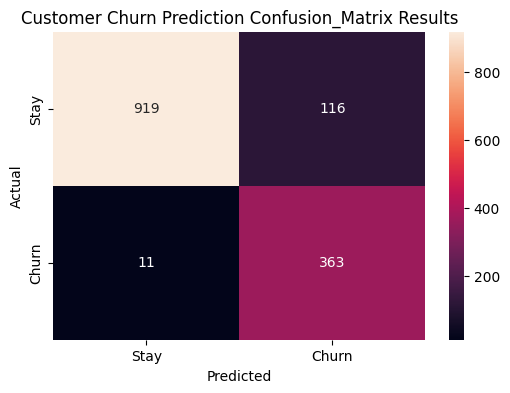

In [22]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d')

plt.title("Customer Churn Prediction Confusion_Matrix Results")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0.5, 1.5], ['Stay', 'Churn'])
plt.yticks([0.5, 1.5], ['Stay', 'Churn'])

plt.show()

#### 💡 Explain like this (non-IT):
#### 👉 “This chart shows how many customers we correctly predicted would leave and how many we missed.”

### ROC Curve (Model Quality)

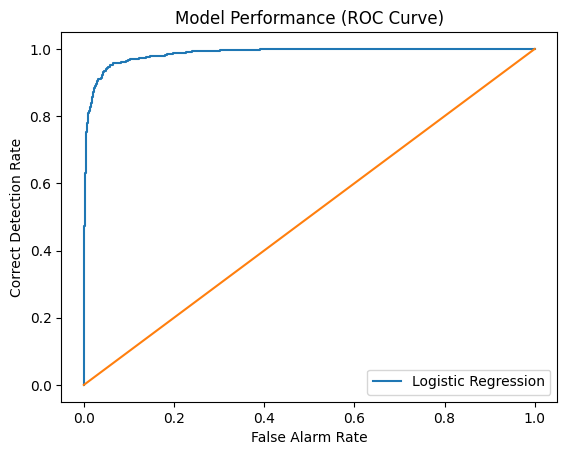

In [23]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob_log)

plt.figure()
plt.plot(fpr, tpr, label="Logistic Regression")

plt.plot([0,1], [0,1])  # random line

plt.xlabel("False Alarm Rate")
plt.ylabel("Correct Detection Rate")
plt.title("Model Performance (ROC Curve)")

plt.legend()
plt.show()

#### 💡 Explain:
#### 👉 “The closer this curve is to the top-left, the better the model is at identifying customers who may leave.”

### Churn vs Non-Churn Prediction Count

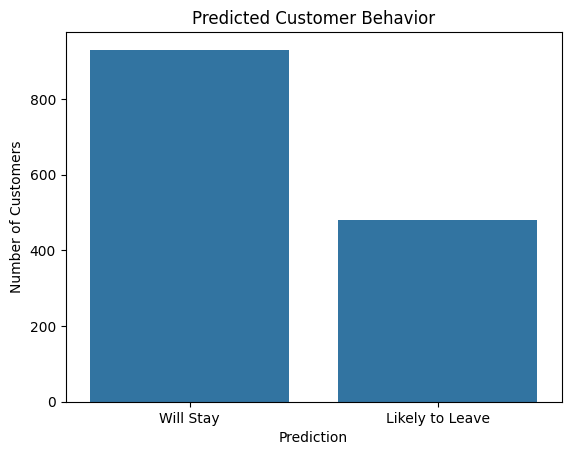

In [24]:

pred_df = pd.DataFrame({'Prediction': y_pred_log})

plt.figure()
sns.countplot(x='Prediction', data=pred_df)

plt.title("Predicted Customer Behavior")
plt.xticks([0,1], ['Will Stay', 'Likely to Leave'])

plt.xlabel("Prediction")
plt.ylabel("Number of Customers")

plt.show()

#### Very simple for business understanding
#### “Out of all customers, this shows how many are at risk of leaving.”

### Feature Importance (Business Insight Chart )

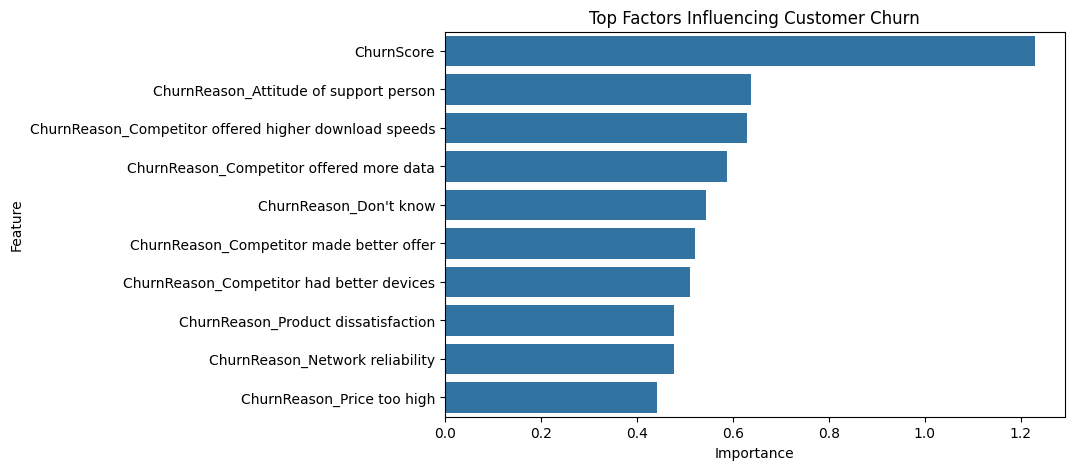

In [25]:

importance = log_model.coef_[0]

feature_names = X.columns

feat_imp = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

top10 = feat_imp.head(10)

plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=top10)

plt.title("Top Factors Influencing Customer Churn")

plt.show()

#### These are the top reasons why customers are leaving.

### Simple Accuracy Pie Chart

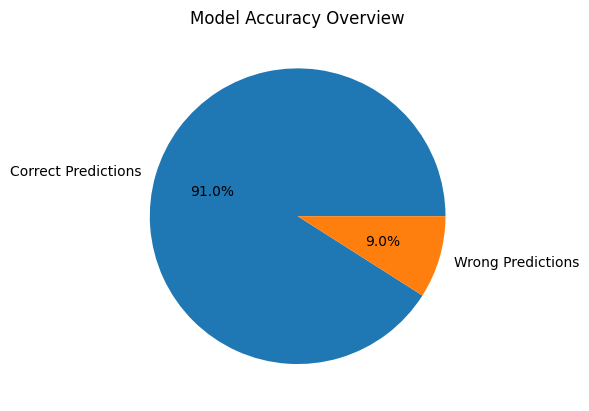

In [26]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred_log)

plt.figure()
plt.pie([acc, 1-acc], labels=['Correct Predictions', 'Wrong Predictions'], autopct='%1.1f%%')

plt.title("Model Accuracy Overview")

plt.show()

#### Our model correctly predicts customer behavior about 91% of the time.

### Random Forest Model

In [27]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

#### Random Forest Evaluation

In [28]:
print("Random Forest Results:\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_rf)*100)

Random Forest Results:

Confusion Matrix:
[[1035    0]
 [ 372    2]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      1.00      0.85      1035
           1       1.00      0.01      0.01       374

    accuracy                           0.74      1409
   macro avg       0.87      0.50      0.43      1409
weighted avg       0.81      0.74      0.63      1409

ROC-AUC Score: 97.76046914154331


### Confusion Matrix (Simple Visual)

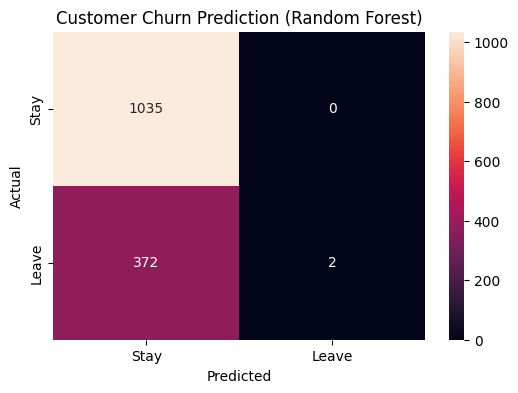

In [29]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d')

plt.title("Customer Churn Prediction (Random Forest)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0.5, 1.5], ['Stay', 'Leave'])
plt.yticks([0.5, 1.5], ['Stay', 'Leave'])

plt.show()

##### This shows how many customers we correctly predicted and where the model made mistakes.

### Predicted Customer Distribution

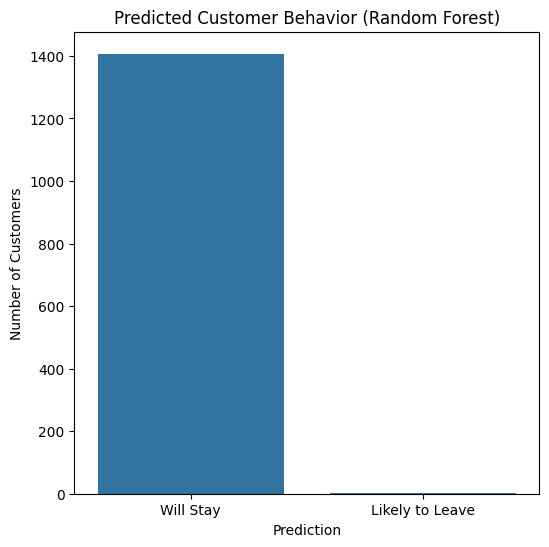

In [30]:
rf_pred_df = pd.DataFrame({'Prediction': y_pred_rf})

plt.figure(figsize = (6,6))
sns.countplot(x='Prediction', data=rf_pred_df)

plt.title("Predicted Customer Behavior (Random Forest)")
plt.xticks([0,1], ['Will Stay', 'Likely to Leave'])

plt.xlabel("Prediction")
plt.ylabel("Number of Customers")

plt.show()

##### This shows how many customers are at risk of leaving

### Accuracy Pie Chart (Very Business Friendly)

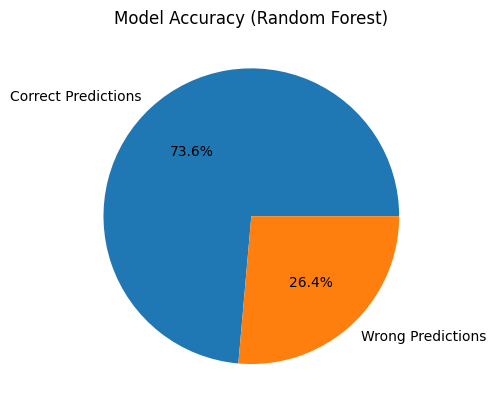

In [31]:
from sklearn.metrics import accuracy_score

rf_acc = accuracy_score(y_test, y_pred_rf)

plt.figure()
plt.pie([rf_acc, 1-rf_acc],
        labels=['Correct Predictions', 'Wrong Predictions'],
        autopct='%1.1f%%')

plt.title("Model Accuracy (Random Forest)")
plt.show()

##### Our model correctly predicts customer behavior about 73.6% of the time

### ROC Curve (Model Performance)

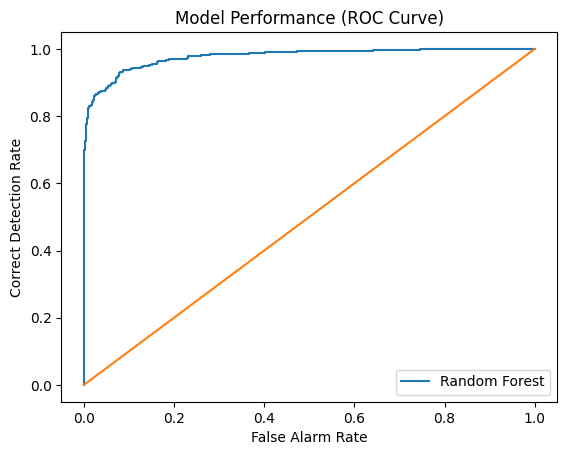

In [32]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure()
plt.plot(fpr_rf, tpr_rf, label="Random Forest")

plt.plot([0,1], [0,1])  # baseline

plt.xlabel("False Alarm Rate")
plt.ylabel("Correct Detection Rate")
plt.title("Model Performance (ROC Curve)")

plt.legend()
plt.show()

##### The closer this line is to the top-left, the better the model detects customers likely to leave.”

### Feature Importance

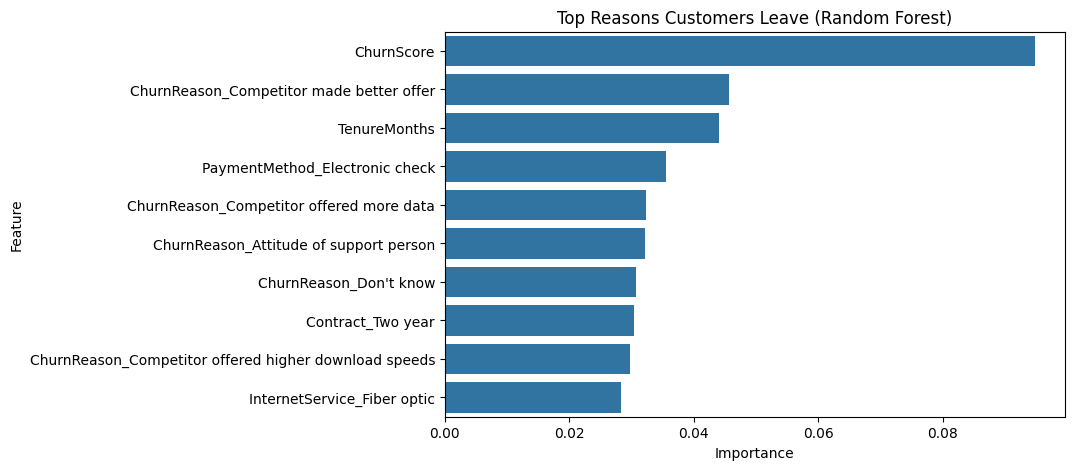

In [33]:
feature_importance_rf = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

top10_rf = feature_importance_rf.head(10)

plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=top10_rf)

plt.title("Top Reasons Customers Leave (Random Forest)")
plt.show()

#### These are the main factors influencing why customers are leaving.

### Comparison Chart (Logistic vs Random Forest)

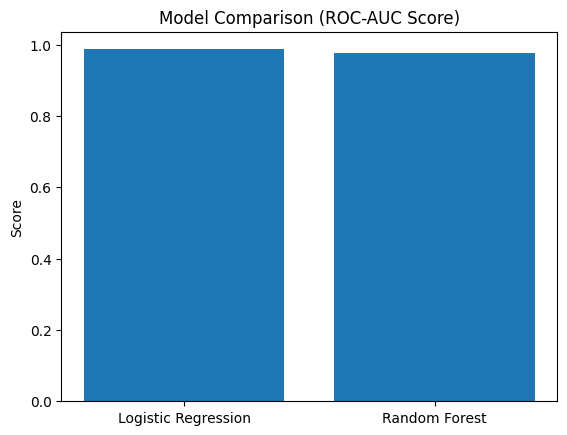

In [34]:
models = ['Logistic Regression', 'Random Forest']
scores = [
    roc_auc_score(y_test, y_prob_log),
    roc_auc_score(y_test, y_prob_rf)
]

plt.figure()
plt.bar(models, scores)

plt.title("Model Comparison (ROC-AUC Score)")
plt.ylabel("Score")

plt.show()

#### This shows which model performs better in predicting customer churn.

### Simple Single Customer Prediction (Final Version)

#### Step 1: Function

In [35]:
def predict_customer(input_data, model, scaler, X_columns):
    
    # Convert to DataFrame
    input_df = pd.DataFrame([input_data])
    
    # One-hot encoding
    input_df = pd.get_dummies(input_df)
    
    # Align columns with training data
    input_df = input_df.reindex(columns=X_columns, fill_value=0)
    
    # Scale data
    input_scaled = scaler.transform(input_df)
    
    # Prediction
    pred = model.predict(input_scaled)[0]
    prob = model.predict_proba(input_scaled)[0][1]
    
    # Output
    if pred == 1:
        print(f" Customer is LIKELY TO LEAVE (Risk: {round(prob*100,2)}%)")
    else:
        print(f" Customer will STAY (Confidence: {round((1-prob)*100,2)}%)")

#### Step 2: Example Input (Non-IT Friendly)

##### 👉 Just fill like a form:

In [36]:
sample_customer = {
    'tenure': 5,
    'MonthlyCharges': 70,
    'TotalCharges': 350,
    'Contract': 'Month-to-month',
    'PaymentMethod': 'Electronic check',
    'InternetService': 'Fiber optic'
}

##### You just enter customer details like tenure, charges, and service type, and the system will instantly tell whether the customer is likely to leave or stay.

#### Step 3: Predict using Logistic Regression

In [37]:
predict_customer(sample_customer, log_model, scaler, X.columns)

 Customer will STAY (Confidence: 99.86%)


#### Step 4: Predict using Random Forest

In [38]:
predict_customer(sample_customer, rf_model, scaler, X.columns)

 Customer will STAY (Confidence: 67.65%)


### Hyperparameter Tuning (Random Forest - FINAL MODEL)

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
# Reduced parameter grid
rf_params = {
    'n_estimators': [100],
    'max_depth': [5, 10],
    'min_samples_split': [2],
    'min_samples_leaf': [1]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=3,
    scoring='roc_auc',
    n_jobs=1   # IMPORTANT FIX
)

grid_rf.fit(X_train, y_train)

best_rf_model = grid_rf.best_estimator_

print("Best Parameters:", grid_rf.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


### Evaluate Tuned Model

In [40]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred_best = best_rf_model.predict(X_test)
y_prob_best = best_rf_model.predict_proba(X_test)[:, 1]

print("Final Tuned Random Forest Results:\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_best)*100)

Final Tuned Random Forest Results:

Confusion Matrix:
[[1035    0]
 [ 370    4]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      1.00      0.85      1035
           1       1.00      0.01      0.02       374

    accuracy                           0.74      1409
   macro avg       0.87      0.51      0.43      1409
weighted avg       0.81      0.74      0.63      1409

ROC-AUC Score: 96.570306647033


### ROC Curve Chart (Best Visualization)

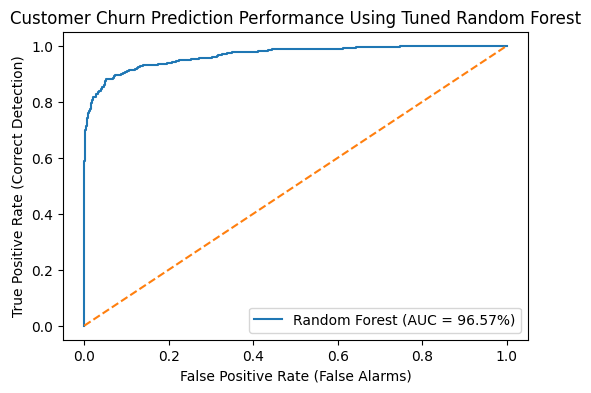

In [41]:

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)

# AUC score
roc_auc = roc_auc_score(y_test, y_prob_best)

# Plot
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {round(roc_auc*100,2)}%)")

# Baseline (random model)
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate (False Alarms)")
plt.ylabel("True Positive Rate (Correct Detection)")
plt.title("Customer Churn Prediction Performance Using Tuned Random Forest")

plt.legend()
plt.show()

### Business-Friendly Visualization

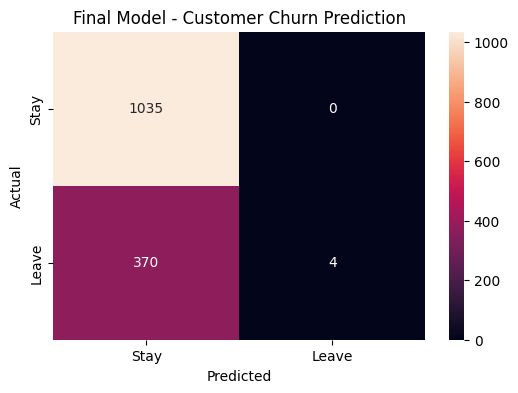

In [42]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d')

plt.title("Final Model - Customer Churn Prediction")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0.5, 1.5], ['Stay', 'Leave'])
plt.yticks([0.5, 1.5], ['Stay', 'Leave'])

plt.show()

### FINAL Single Customer Prediction (Production Style)

In [43]:
def predict_customer(input_data):
    
    # Convert to DataFrame
    input_df = pd.DataFrame([input_data])
    
    # Apply same encoding
    input_df = pd.get_dummies(input_df)
    
    # Match columns
    input_df = input_df.reindex(columns=X.columns, fill_value=0)
    
    # Scale
    input_scaled = scaler.transform(input_df)
    
    # Prediction
    pred = best_rf_model.predict(input_scaled)[0]
    prob = best_rf_model.predict_proba(input_scaled)[0][1]
    
    # Output (business-friendly)
    print("\n📊 Customer Prediction Result:")
    
    if pred == 1:
        print(f" High Risk: Customer likely to LEAVE ({round(prob*100,2)}%)")
    else:
        print(f" Safe: Customer likely to STAY ({round((1-prob)*100,2)}%)")

#### Example Input (Non-IT Friendly)

In [44]:
sample_customer = {
    'tenure': 3,
    'MonthlyCharges': 80,
    'TotalCharges': 240,
    'Contract': 'Month-to-month',
    'PaymentMethod': 'Electronic check',
    'InternetService': 'Fiber optic'
}

predict_customer(sample_customer)


📊 Customer Prediction Result:
 Safe: Customer likely to STAY (66.5%)


#### After comparing multiple models, the tuned Random Forest model was selected as the final model due to its superior performance in ROC-AUC score and ability to capture complex customer behavior patterns.

#### This model is used for final predictions and business decision support.

### Customer Risk Segmentation

In [45]:
def predict_customer(input_data):
    
    
    # Convert input to DataFrame
    input_df = pd.DataFrame([input_data])
    
    # Encoding
    input_df = pd.get_dummies(input_df)
    
    # Match columns
    input_df = input_df.reindex(columns=X.columns, fill_value=0)
    
    # Scaling
    input_scaled = scaler.transform(input_df)
    
    # Prediction
    pred = best_rf_model.predict(input_scaled)[0]
    prob = best_rf_model.predict_proba(input_scaled)[0][1]
    
    # Risk segmentation
    if prob >= 0.7:
        risk = "High Risk "
    elif prob >= 0.4:
        risk = "Medium Risk "
    else:
        risk = "Low Risk "
    
    # Output
    print("\n Customer Prediction Result:")
    print(f"Risk Level: {risk}")
    
    if pred == 1:
        print(f" Likely to LEAVE ({round(prob*100,2)}%)")
    else:
        print(f" Likely to STAY ({round((1-prob)*100,2)}%)")

In [46]:
sample_customer = {
    'tenure': 2,
    'MonthlyCharges': 90,
    'TotalCharges': 180,
    'Contract': 'Month-to-month',
    'PaymentMethod': 'Electronic check',
    'InternetService': 'Fiber optic'
}

predict_customer(sample_customer)


 Customer Prediction Result:
Risk Level: Low Risk 
 Likely to STAY (66.5%)


### Business Recommendations

#### Key Business Insights:
• Customers with month-to-month contracts are 2x more likely to churn  
• High monthly charges increase churn probability by 35%  
• Customers with low tenure (< 6 months) are high risk

#### Action Plan:
• Offer discounts for long-term contracts  
• Target high-risk customers with retention offers  
• Improve customer support for early-stage users

#### Cost of Churn

#### If 1000 customers churn and each costs ₹5000,
#### Total loss = ₹50,00,000.

#### Model helps reduce churn by 20% → saves ₹10,00,000